# Multi-Window-Finder paper and reference notebook

Does moving the logarithm change the candidate window sizes? How much does
the rule for combining those candidates change the estimate?
This notebook reproduces the differences discussed in [STUMPY issue #1062](https://github.com/stumpy-dev/stumpy/issues/1062#issuecomment-2605449546)
using two synthetic signals with known periods and an excerpt from the UCR
archive used in the paper's evaluation.

Run top to bottom with NumPy, pandas, and Matplotlib in a Python Jupyter
kernel. The synthetic examples run offline. The UCR example downloads a
pinned copy or uses a local copy selected by the `MWF_UCR_PATH` environment
variable.

## What the sources compute

For a window size $w$, let $r_j(w)$ be the absolute deviation of rolling
mean $j$ from the mean of the rolling means. Algorithm 1 in the
[paper](https://kdd-milets.github.io/milets2021/papers/MiLeTS2021_paper_9.pdf)
scores $w$ with $\sum_j \log r_j(w)$. The authors'
[reference notebook](https://drive.google.com/file/d/1R7jbby4phk5pSEbkS3IhlHti9NyMW5Zi/view)
uses $\log\left(\sum_j r_j(w)\right)$. Both identify valleys by
looking for an increase in the sign of adjacent score differences.

The paper describes valleys near successive multiples of the first
valley. We use their one-based order $k$ as the harmonic divisor and
average $w_k/k$ over all detected valleys in the grid, consistent
with that description. As printed, line 9 instead divides by the
valley's zero-based **grid index plus one**. The source comparison
reports that literal reading too.

The reference notebook divides its first three valley sizes by
$1,2,3$ and combines them with weights $0.80,0.15,0.05$. With one
or two valleys it returns the first valley. Its function raises
with no valleys. Here an empty set is reported as a missing estimate.
The comparison reports window estimates in samples.

In [1]:
import hashlib
import os
from pathlib import Path
from urllib.error import URLError
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


n_samples = 8192
t = np.arange(n_samples)
rng = np.random.default_rng(1062)
examples = {}
known_periods = {}
for period in (83, 137):
    phase = 2 * np.pi * t / period
    label = f"Synthetic {period}"
    examples[label] = (
        np.sin(phase) + 0.35 * np.cos(2 * phase)
        + rng.normal(0, 0.25, n_samples)
    )
    known_periods[label] = period

The benchmark excerpt is the first 8,192 samples of
`001_UCR_Anomaly_DISTORTED1sddb40_35000_52000_52620.txt` from the
[UCR Time Series Anomaly Archive](https://research.cs.wisc.edu/dbworld/messages/2021-08/1629756974.html).
This lies wholly within the first 35,000 samples, the training prefix
indicated by the filename. The excerpt has no labeled ground-truth
window size.

In [2]:
ucr_label = "UCR 001 prefix"
ucr_filename = "001_UCR_Anomaly_DISTORTED1sddb40_35000_52000_52620.txt"
ucr_url = (
    "https://raw.githubusercontent.com/ML-KULeuven/dtaianomaly/"
    "7755553ebb48de483d13429699f5eefd120ba4b8/"
    "data/UCR-time-series-anomaly-archive/" + ucr_filename
)
ucr_sha256 = "4a9c39e6d2cbd819909df7d20cf553afa995daa3155611f9972960199973bca3"
local_ucr = os.getenv("MWF_UCR_PATH")
ucr_bytes = None

if local_ucr:
    ucr_bytes = Path(local_ucr).read_bytes()
else:
    try:
        with urlopen(ucr_url, timeout=15) as response:
            ucr_bytes = response.read()
    except (URLError, TimeoutError) as error:
        print(f"Skipping UCR example ({error}). Set MWF_UCR_PATH to run offline.")

if ucr_bytes is not None:
    if hashlib.sha256(ucr_bytes).hexdigest() != ucr_sha256:
        raise ValueError("UCR file does not match the pinned copy")
    values = np.fromstring(ucr_bytes.decode("ascii"), sep=" ")
    assert values.size >= n_samples
    examples[ucr_label] = values[:n_samples]

## Compare the formulas on the same grid

Each comparison uses the same input, windows $10,20,\ldots,1000$,
and rolling means for both scores. The reference notebook keeps
only the first $n-1000+1$ rolling means at every window size, so
each score uses the same number of residuals. We use that convention
here. To isolate weighting from the number of candidates, we show
the equal-weight mean of the first three alongside the source rules.

Logarithms are natural. An exact zero residual produces $-\infty$
in the paper score. We keep that behavior without adding an epsilon
and check that the examples have finite scores.

In [3]:
paper_score = "Sum of logs"
reference_score = "Log of sum"
weights = np.array([0.80, 0.15, 0.05])
reference_grid = np.arange(10, 1001, 10)
paper_grid = np.arange(10, 1001)


def score_curves(values, grid, *, trim):
    cumulative = np.cumsum(values, dtype=float)
    n_common = values.size - grid[-1] + 1
    sum_of_logs = np.empty(grid.size)
    residual_sums = np.empty(grid.size)
    with np.errstate(divide="ignore"):
        for i, w in enumerate(grid):
            avg = cumulative[w - 1:].copy()
            avg[1:] -= cumulative[:-w]
            avg /= w
            if trim:
                avg = avg[:n_common]
            residuals = np.abs(avg - avg.mean())
            sum_of_logs[i] = np.log(residuals).sum()
            residual_sums[i] = residuals.sum()
        log_of_sum = np.log(residual_sums)
    return {paper_score: sum_of_logs, reference_score: log_of_sum}, residual_sums


def valley_indices(scores):
    with np.errstate(invalid="ignore"):
        return np.flatnonzero(np.diff(np.sign(np.diff(scores))) > 0) + 1


def estimate_windows(candidates):
    if candidates.size == 0:
        return np.nan, np.nan, np.nan
    harmonic_estimates = candidates / np.arange(1, candidates.size + 1)
    mean_all = harmonic_estimates.mean()
    if candidates.size < 3:
        return mean_all, np.nan, float(candidates[0])
    first_three = harmonic_estimates[:3]
    return mean_all, first_three.mean(), weights @ first_three

In [4]:
matched_curves = {}
matched_rows = []
for name, values in examples.items():
    curves, residual_sums = score_curves(values, reference_grid, trim=True)
    matched_curves[name] = curves
    for scores in curves.values():
        assert np.isfinite(scores).all()
    # The outer log is increasing, so it preserves the valleys here.
    np.testing.assert_array_equal(
        valley_indices(curves[reference_score]), valley_indices(residual_sums)
    )
    for score_name, scores in curves.items():
        candidates = reference_grid[valley_indices(scores)]
        mean_all, mean_first_three, weighted_first_three = estimate_windows(candidates)
        matched_rows.append({
            "Series": name,
            "Score": score_name,
            "First three valleys": candidates[:3].tolist(),
            "Valleys": candidates.size,
            "Mean of all": mean_all,
            "Mean of first three": mean_first_three,
            "Reference weighting": weighted_first_three,
        })

matched = pd.DataFrame(matched_rows).set_index(["Series", "Score"])
display(matched.round(2))

First three valleys  ...  Reference weighting
Series         Score                            ...                     
Synthetic 83   Sum of logs      [80, 170, 250]  ...                80.92
               Log of sum       [80, 170, 250]  ...                80.92
Synthetic 137  Sum of logs     [140, 270, 410]  ...               139.08
               Log of sum      [140, 270, 410]  ...               139.08
UCR 001 prefix Sum of logs      [20, 200, 390]  ...                37.50
               Log of sum      [210, 420, 630]  ...               210.00

[6 rows x 5 columns]

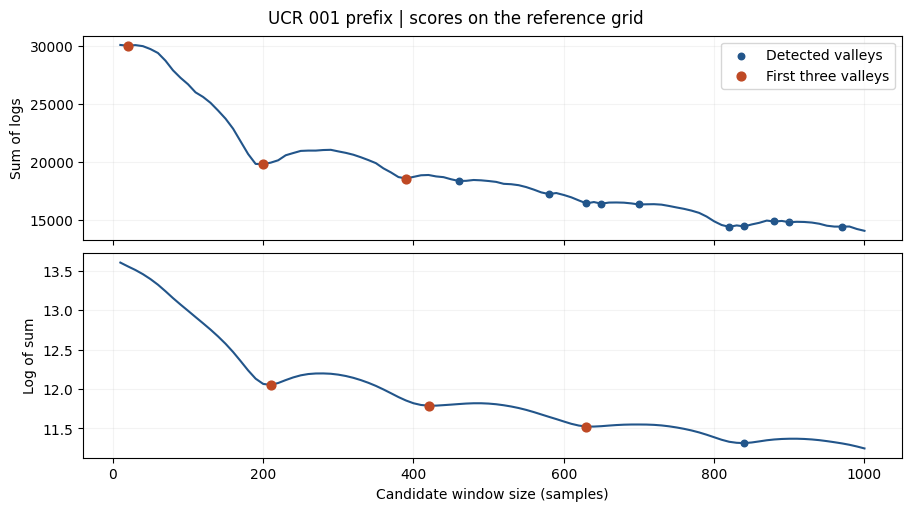

In [5]:
plot_name = ucr_label if ucr_label in examples else "Synthetic 83"
curves = matched_curves[plot_name]
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True, layout="constrained")
fig.suptitle(f"{plot_name} | scores on the reference grid")
for axis, (score_name, scores) in zip(axes, curves.items()):
    valleys = valley_indices(scores)
    axis.plot(reference_grid, scores, color="#22558a", linewidth=1.5)
    axis.scatter(
        reference_grid[valleys], scores[valleys],
        color="#22558a", s=22, label="Detected valleys",
    )
    first_three = valleys[:3]
    axis.scatter(
        reference_grid[first_three], scores[first_three],
        color="#bf4924", s=40, label="First three valleys", zorder=3,
    )
    axis.set_ylabel(score_name)
    axis.grid(alpha=0.15)
axes[0].legend(loc="best")
axes[-1].set_xlabel("Candidate window size (samples)")
plt.show()

## Compare the source configurations

The paper's pseudocode scans integer windows from 10 through 1,000
and keeps the full rolling mean at each size. The reference function
uses `range(start, end, 10)`. We pass `start=10, end=1010` so both
grids end at 1,000. The difference between the source estimates
includes the grid and trimming choices as well as the scoring and
aggregation rules. The matched table above controls those choices.

In [6]:
source_rows = []
for name, values in examples.items():
    curves, _ = score_curves(values, paper_grid, trim=False)
    scores = curves[paper_score]
    assert np.isfinite(scores).all()
    paper_indices = valley_indices(scores)
    paper_candidates = paper_grid[paper_indices]
    paper_estimate, _, _ = estimate_windows(paper_candidates)
    literal_estimate = (
        np.mean(paper_candidates / (paper_indices + 1))
        if paper_indices.size else np.nan
    )
    source_rows.append({
        "Series": name,
        "Known period": known_periods.get(name, np.nan),
        "Paper first three valleys": paper_candidates[:3].tolist(),
        "Paper valleys": paper_candidates.size,
        "Paper (valley order)": paper_estimate,
        "Paper (literal grid index)": literal_estimate,
        "Reference notebook": matched.loc[(name, reference_score), "Reference weighting"],
    })

display(pd.DataFrame(source_rows).set_index("Series").round(2))

,Known period,Paper first three valleys,Paper valleys,Paper (valley order),Paper (literal grid index),Reference notebook
Series,,,,,,
Synthetic 83,83.0,"[83, 117, 166]",25,46.52,1.03,80.92
Synthetic 137,137.0,"[137, 191, 194]",32,45.42,1.02,139.08
UCR 001 prefix,NaN,"[19, 21, 27]",114,11.33,1.04,210.00


## What changed

- **Score order.** On the UCR excerpt with the shared grid and trimming,
  the paper score's first three valleys are 20, 200, and 390. The
  reference score's are 210, 420, and 630. At fixed reference weights,
  the estimates are 37.50 and 210.00 samples, respectively. Taking
  the outer log preserves the ordering of positive residual sums.
  Applying the log to each residual before summing can change that
  ordering.
- **Candidate combination.** Holding the UCR paper score fixed,
  averaging all harmonic estimates gives 90.08 samples. Restricting
  the mean to three gives 83.33. Applying the reference weights to
  those same three gives 37.50, because the first valley gets 80% of
  the weight. With the reference score, all three schemes give 210
  because the detected valleys are exact multiples of 210 on this grid.
- **Source configurations.** With the paper's dense grid and full
  rolling means, the 83- and 137-sample signals yield 25 and 32
  valleys. Even though their first valleys match the known periods,
  the subsequent valleys shift the harmonic means to 46.52 and
  45.42. The reference estimates are 80.92 and 139.08. The literal
  grid-index division yields estimates near one sample, which
  conflicts with the paper's description of dividing successive
  multiples of the first valley.

The synthetic cases have known periods. The UCR excerpt demonstrates
sensitivity to the two formulas without establishing which estimate
is correct for that recording.